# Hotel Booking Cancellation Prediction



## 1. Import libraries

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## 2. Load the dataset

In [68]:
df = pd.read_csv("hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [69]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (119390, 32)

Column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [71]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


## 3. Understand the target variable

In [72]:
# 0 = not cancelled, 1 = cancelled
df["is_canceled"].value_counts()

,count
is_canceled,
0,75166
1,44224


In [73]:
cancellation_percent = df["is_canceled"].value_counts(normalize=True).mul(100).round(2)
print(cancellation_percent)

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


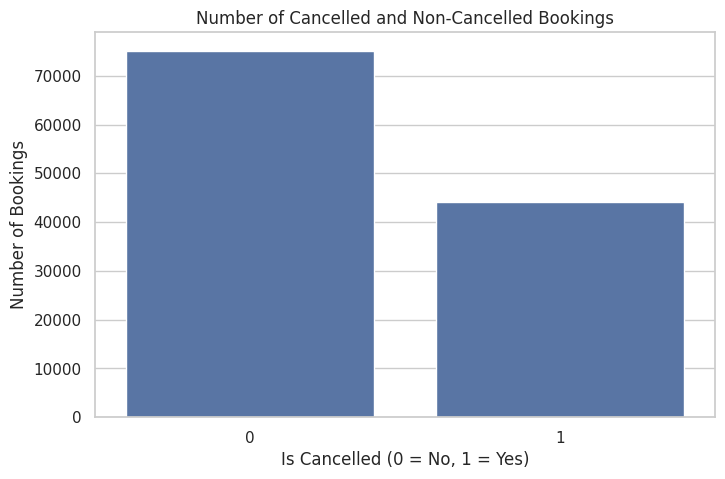

In [74]:
sns.countplot(data=df, x="is_canceled")
plt.title("Number of Cancelled and Non-Cancelled Bookings")
plt.xlabel("Is Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.show()

## 4. Check data quality

In [75]:
# Count missing values and calculate their percentage
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percent": (df.isnull().mean() * 100).round(2)
})
missing_summary = missing_summary[missing_summary["Missing Values"] > 0].sort_values(
    "Missing Percent", ascending=False
)
missing_summary

,Missing Values,Missing Percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [76]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique values in each column:")
df.nunique().sort_values()

Exact duplicate rows: 31994
Unique values in each column:


,0
hotel,2
is_canceled,2
is_repeated_guest,2
arrival_date_year,3
deposit_type,3
reservation_status,3
customer_type,4
babies,5
meal,5
distribution_channel,5


## 5. Clean the data

We keep a copy of the original data and clean `df` for the remaining analysis. Exact duplicate rows are removed. `company` and `agent` often have many missing values in this dataset, so they are dropped here. Missing countries are labelled `Unknown` rather than being assigned the most common country. Missing `children` values are filled with the median.

In [77]:
df = df.copy()
rows_before = len(df)

df = df.drop_duplicates()

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())

Rows before removing duplicates: 119390
Rows after removing duplicates: 87396
Duplicate rows remaining: 0


In [78]:
# Check missing-value percentages before dropping columns
(df.isnull().mean() * 100).sort_values(ascending=False).head(10)

,0
company,93.982562
agent,13.951439
country,0.517186
children,0.004577
arrival_date_month,0.000000
arrival_date_week_number,0.000000
hotel,0.000000
is_canceled,0.000000
stays_in_weekend_nights,0.000000
arrival_date_day_of_month,0.000000


In [79]:
# Drop columns that commonly contain a very large number of missing values
columns_to_drop = [col for col in ["company", "agent"] if col in df.columns]
df = df.drop(columns=columns_to_drop)

# Fill remaining missing values in selected columns
if "country" in df.columns:
    df["country"] = df["country"].fillna("Unknown")

if "children" in df.columns:
    df["children"] = df["children"].fillna(df["children"].median())

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


In [80]:
# Confirm the cleaned data
print("Cleaned shape:", df.shape)
print("\nMissing values by column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

Cleaned shape: (87396, 30)

Missing values by column:
Series([], dtype: int64)

Duplicate rows: 26


## 6. Add useful features

These simple features make booking patterns easier to study. They are useful for EDA and can later be considered for modelling.

In [81]:
# Total length of stay
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

# Total number of guests
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

df[["stays_in_weekend_nights", "stays_in_week_nights", "total_nights",
    "adults", "children", "babies", "total_guests"]].head()

,stays_in_weekend_nights,stays_in_week_nights,total_nights,adults,children,babies,total_guests
0,0,0,0,2,0.0,0,2.0
1,0,0,0,2,0.0,0,2.0
2,0,1,1,1,0.0,0,1.0
3,0,1,1,1,0.0,0,1.0
4,0,2,2,2,0.0,0,2.0


In [82]:
# Convert arrival month into a consistent month order for plotting
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

if "arrival_date_month" in df.columns:
    df["arrival_date_month"] = pd.Categorical(
        df["arrival_date_month"], categories=month_order, ordered=True
    )

In [83]:
# Check unusual values before deciding how to handle them
print("Bookings with zero guests:", (df["total_guests"] == 0).sum())
print("Bookings with zero nights:", (df["total_nights"] == 0).sum())
print("Negative ADR values:", (df["adr"] < 0).sum())

Bookings with zero guests: 166
Bookings with zero nights: 651
Negative ADR values: 1


**Note:** These checks identify unusual records but do not automatically delete them. Investigate them first, because unusual values are not always errors.

## 7. EDA: Cancellation patterns

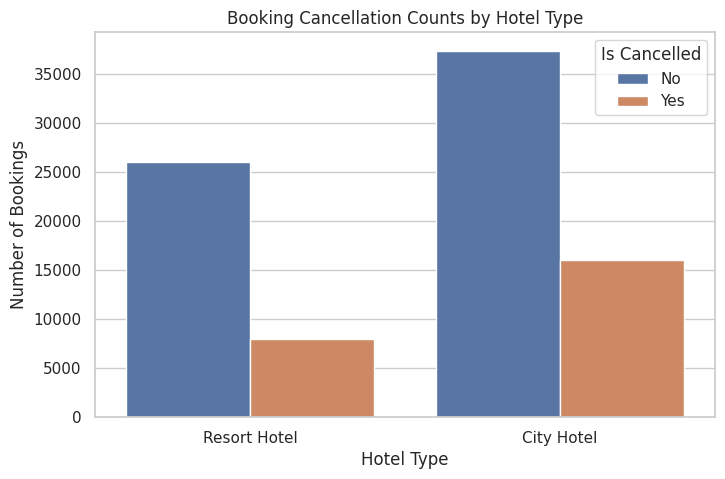

In [84]:
sns.countplot(data=df, x="hotel", hue="is_canceled")
plt.title("Booking Cancellation Counts by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.legend(title="Is Cancelled", labels=["No", "Yes"])
plt.show()

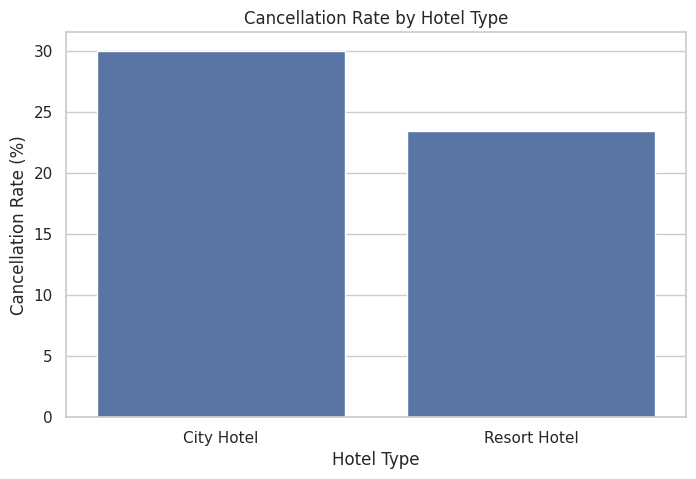

In [85]:
# Cancellation rate is more useful than raw counts when group sizes differ
hotel_cancel_rate = df.groupby("hotel", observed=False)["is_canceled"].mean().mul(100).reset_index()
hotel_cancel_rate.columns = ["hotel", "cancellation_rate"]

sns.barplot(data=hotel_cancel_rate, x="hotel", y="cancellation_rate")
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

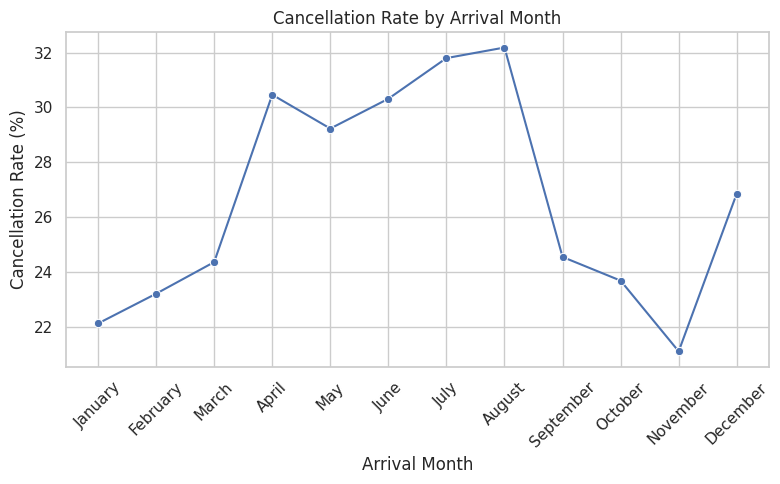

In [86]:
monthly_cancel_rate = df.groupby("arrival_date_month", observed=False)["is_canceled"].mean().mul(100).reset_index()

sns.lineplot(data=monthly_cancel_rate, x="arrival_date_month", y="is_canceled", marker="o")
plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

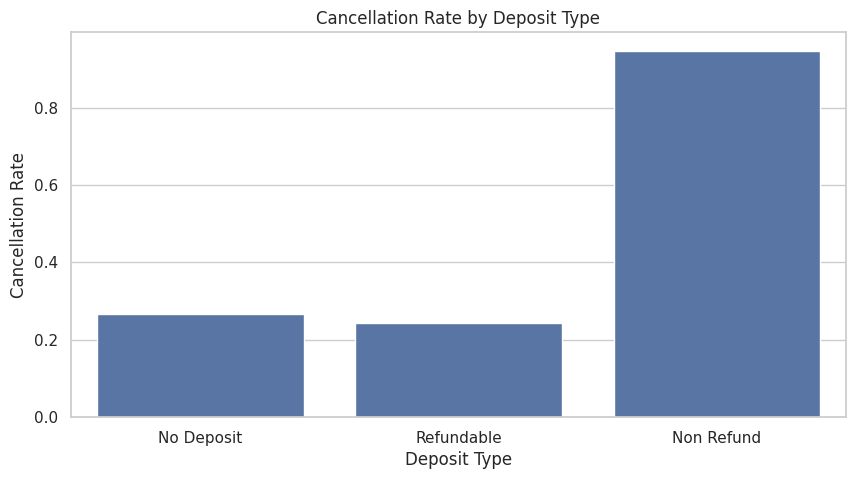

In [87]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="deposit_type", y="is_canceled", errorbar=None)
plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate")
plt.show()

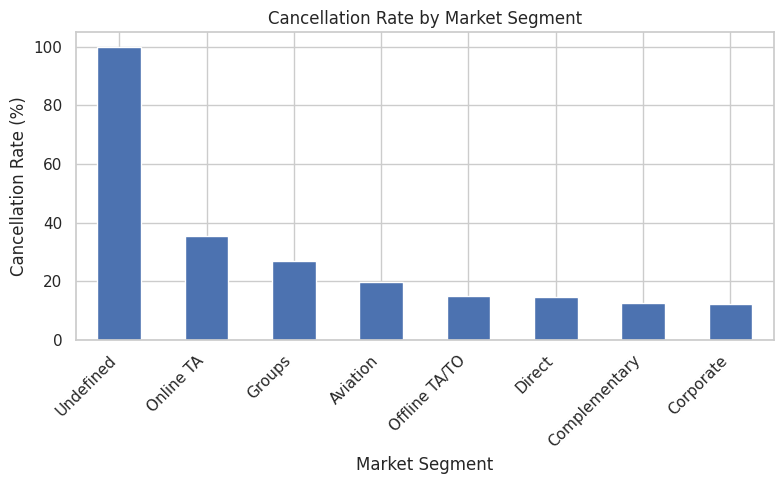

In [88]:
# Market segment cancellation rate, shown from highest to lowest
segment_rate = df.groupby("market_segment", dropna=False)["is_canceled"].mean().mul(100).sort_values(ascending=False)

segment_rate.plot(kind="bar")
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 8. EDA: Booking lead time and prices

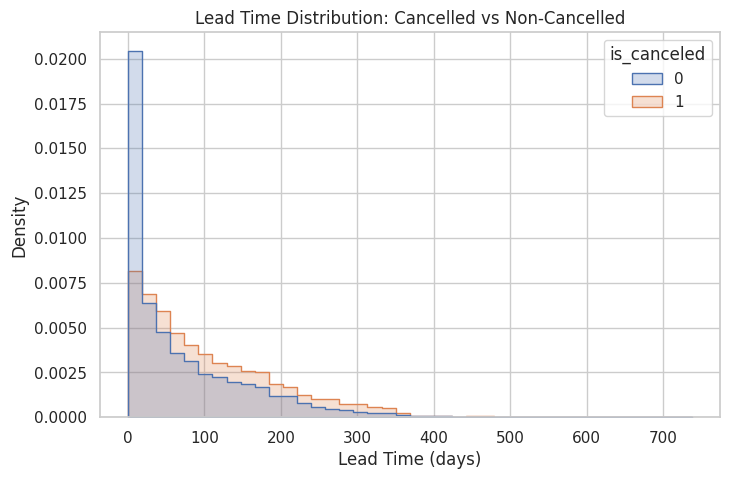

In [89]:
sns.histplot(data=df, x="lead_time", hue="is_canceled", bins=40, stat="density",
             common_norm=False, element="step")
plt.title("Lead Time Distribution: Cancelled vs Non-Cancelled")
plt.xlabel("Lead Time (days)")
plt.ylabel("Density")
plt.show()

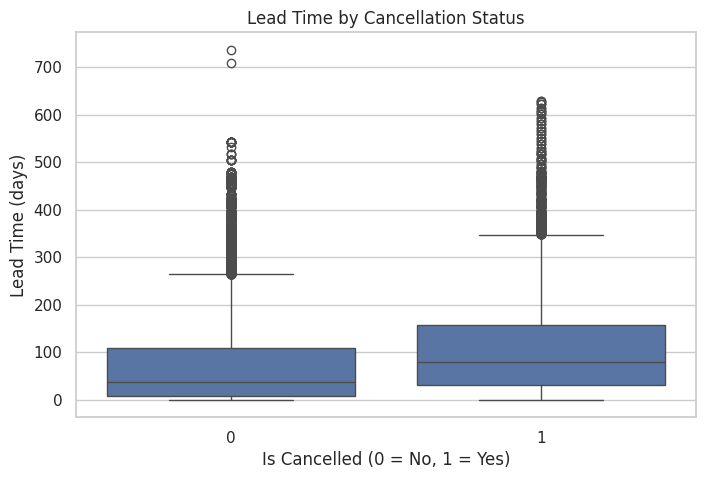

In [90]:
sns.boxplot(data=df, x="is_canceled", y="lead_time")
plt.title("Lead Time by Cancellation Status")
plt.xlabel("Is Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Lead Time (days)")
plt.show()

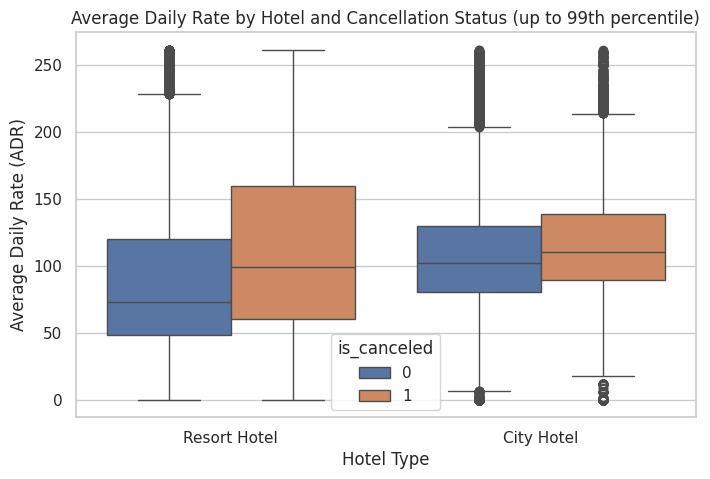

In [91]:
# ADR means Average Daily Rate. Limit the displayed range to make the main pattern easier to see.
adr_plot = df[df["adr"].between(0, df["adr"].quantile(0.99))]

sns.boxplot(data=adr_plot, x="hotel", y="adr", hue="is_canceled")
plt.title("Average Daily Rate by Hotel and Cancellation Status (up to 99th percentile)")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")
plt.show()

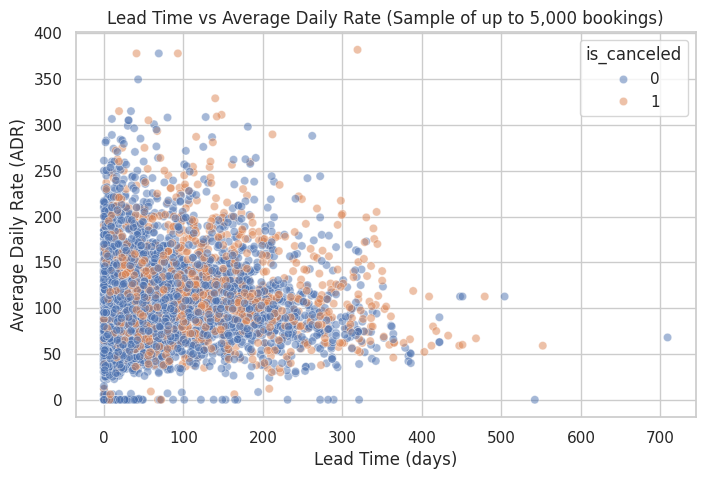

In [92]:
sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=42),
                x="lead_time", y="adr", hue="is_canceled", alpha=0.5)
plt.title("Lead Time vs Average Daily Rate (Sample of up to 5,000 bookings)")
plt.xlabel("Lead Time (days)")
plt.ylabel("Average Daily Rate (ADR)")
plt.show()

## 9. EDA: Stay length and guest information

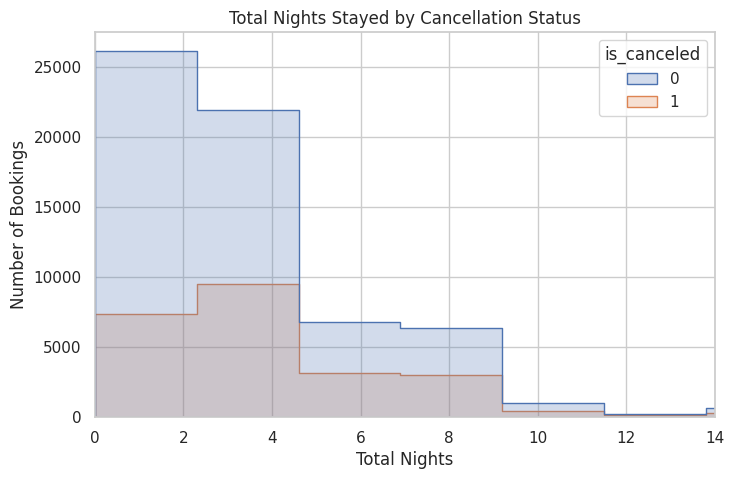

In [93]:
sns.histplot(data=df, x="total_nights", hue="is_canceled", bins=30,
             multiple="layer", element="step")
plt.title("Total Nights Stayed by Cancellation Status")
plt.xlabel("Total Nights")
plt.ylabel("Number of Bookings")
plt.xlim(0, df["total_nights"].quantile(0.99))
plt.show()

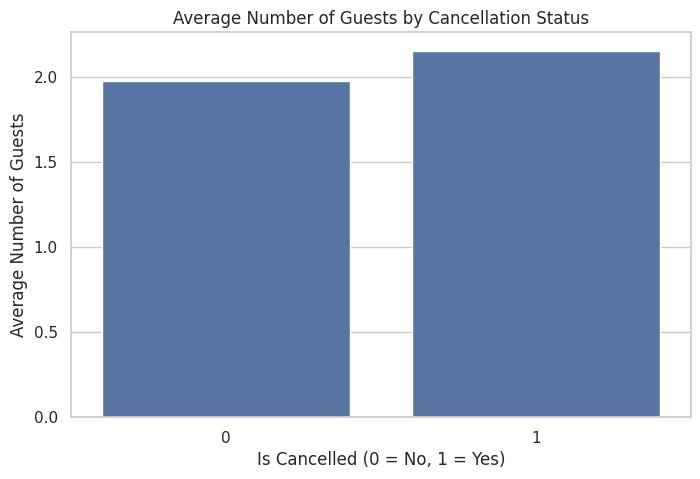

In [94]:
sns.barplot(data=df, x="is_canceled", y="total_guests", errorbar=None)
plt.title("Average Number of Guests by Cancellation Status")
plt.xlabel("Is Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Average Number of Guests")
plt.show()

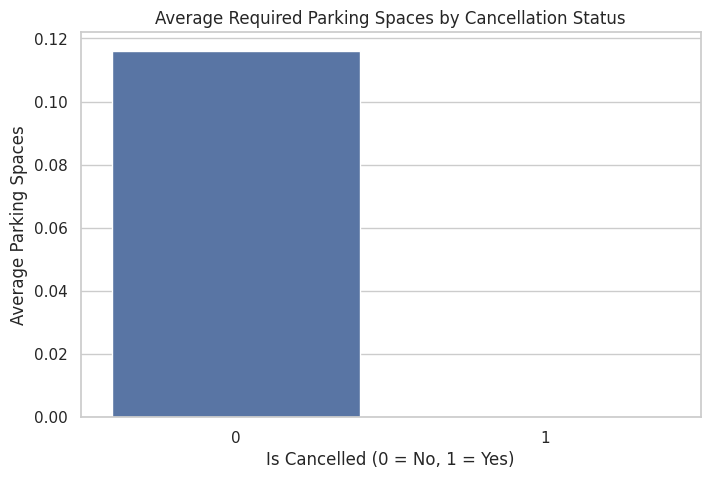

In [95]:
sns.barplot(data=df, x="is_canceled", y="required_car_parking_spaces", errorbar=None)
plt.title("Average Required Parking Spaces by Cancellation Status")
plt.xlabel("Is Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Average Parking Spaces")
plt.show()

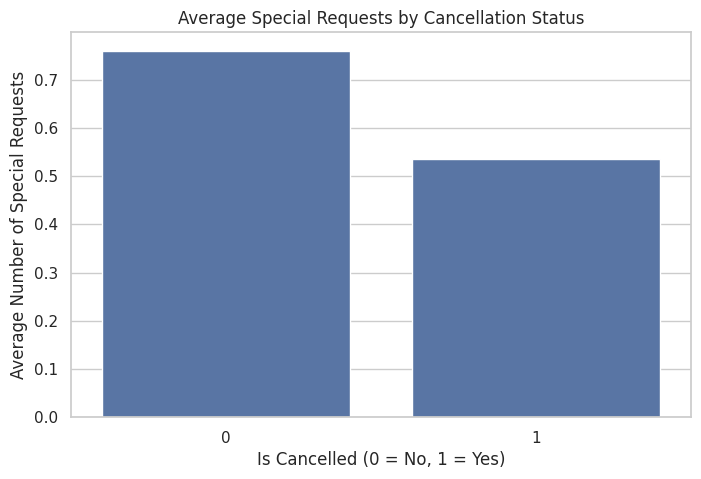

In [96]:
sns.barplot(data=df, x="is_canceled", y="total_of_special_requests", errorbar=None)
plt.title("Average Special Requests by Cancellation Status")
plt.xlabel("Is Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Average Number of Special Requests")
plt.show()

## 10. Correlation between numeric features

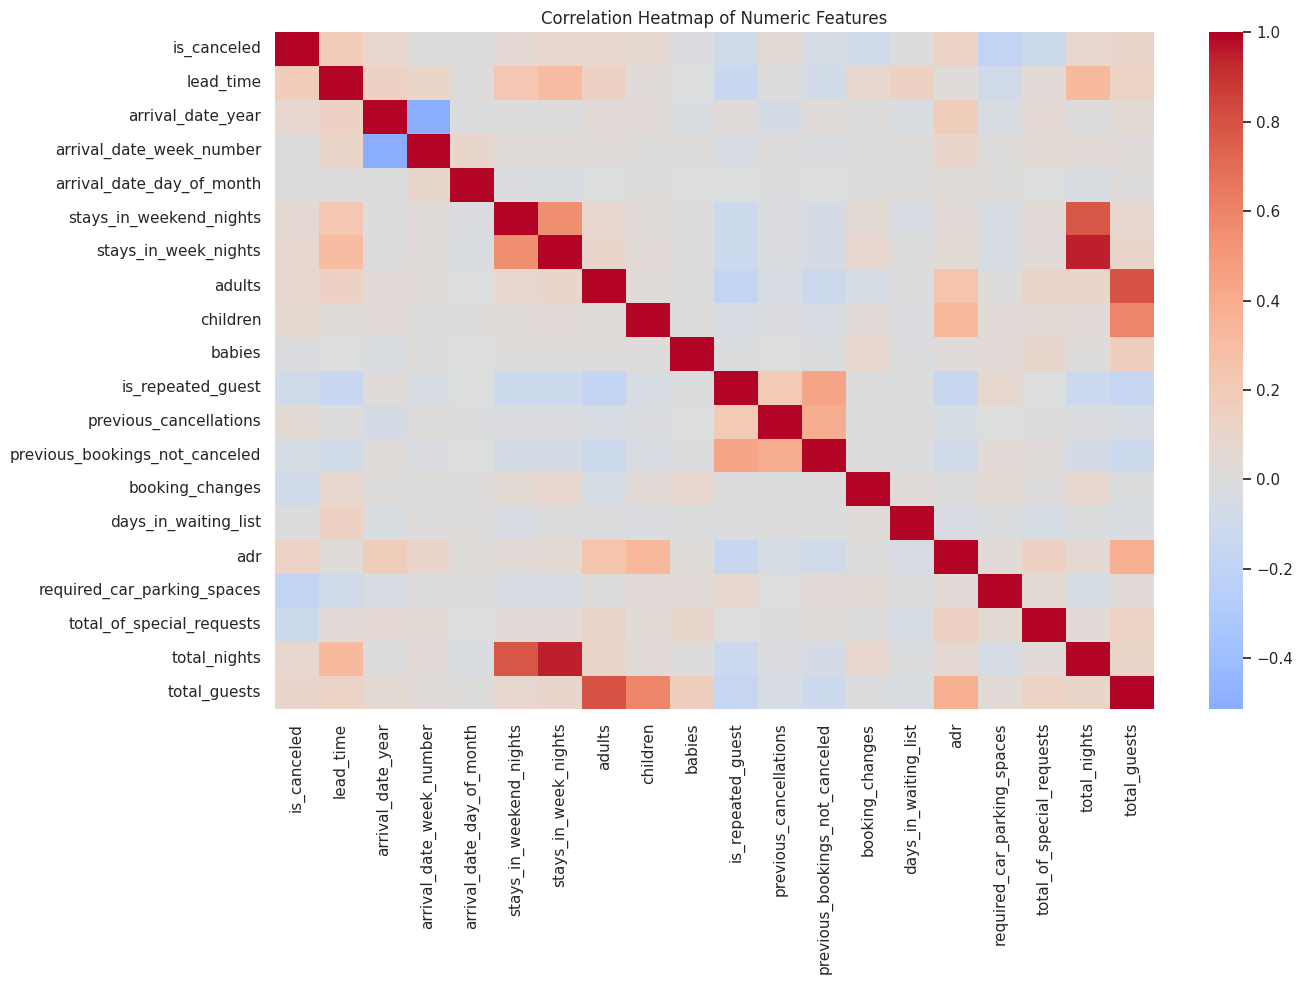

In [97]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

## 11. Final data checks and save cleaned data

In [98]:
print("Final dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df.head()

Final dataset shape: (87396, 32)
Total missing values: 0
Duplicate rows: 26


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights,total_guests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,0,Transient,75.0,0,0,Check-Out,2015-07-02,1,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,0,Transient,98.0,0,1,Check-Out,2015-07-03,2,2.0


In [99]:
# Optional: save a cleaned copy for later modelling
df.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Cleaned dataset saved as hotel_bookings_cleaned.csv")

Cleaned dataset saved as hotel_bookings_cleaned.csv


#Model Training and Evaluation

In [100]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

In [101]:
# Remove columns that reveal the booking outcome
X = df.drop(
    columns=["is_canceled", "reservation_status",
             "reservation_status_date"],
    errors="ignore"
)

y = df["is_canceled"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (87396, 29)
Target: (87396,)


In [102]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (69916, 29)
Testing data: (17480, 29)


In [103]:
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [104]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully")

Logistic Regression trained successfully


In [105]:
print("Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("Precision:",
      precision_score(y_test, lr_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, lr_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, lr_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, lr_probabilities))

print(classification_report(y_test, lr_predictions))

Accuracy: 0.7950800915331808
Precision: 0.6785401459854015
Recall: 0.48366285119667013
F1 Score: 0.5647630619684083
ROC-AUC: 0.8442786709275143
              precision    recall  f1-score   support

           0       0.82      0.91      0.87     12675
           1       0.68      0.48      0.56      4805

    accuracy                           0.80     17480
   macro avg       0.75      0.70      0.72     17480
weighted avg       0.78      0.80      0.78     17480



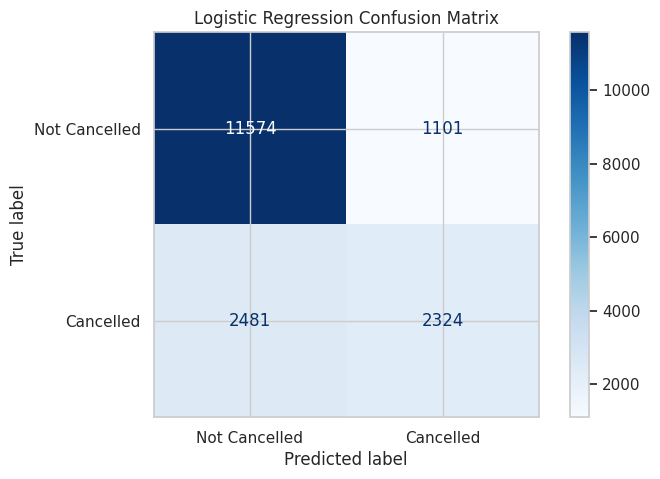

In [106]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    display_labels=["Not Cancelled", "Cancelled"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [107]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully")

Random Forest trained successfully


In [108]:
print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, rf_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_probabilities))

Accuracy: 0.8395881006864988
Precision: 0.7646125363660408
Recall: 0.6016649323621228
F1 Score: 0.6734218495224784
ROC-AUC: 0.8974200034070362


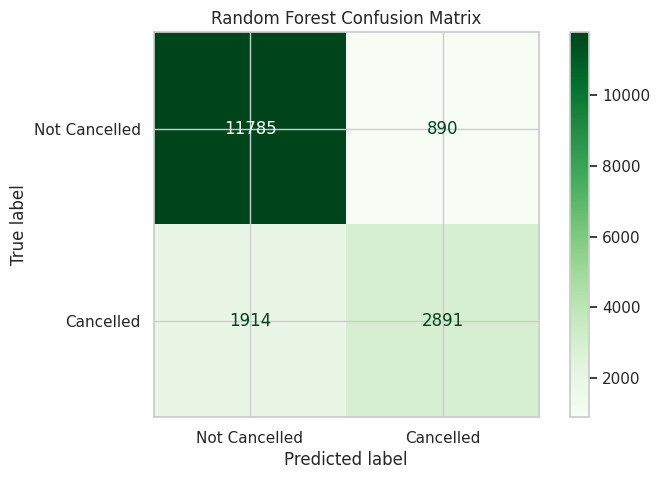

In [109]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Not Cancelled", "Cancelled"],
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

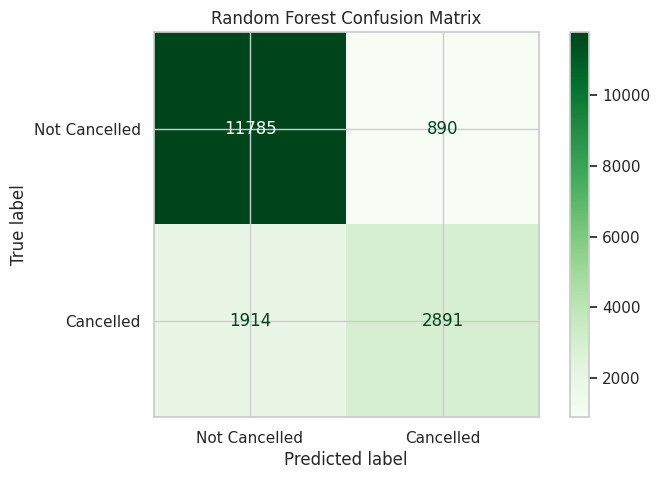

In [110]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Not Cancelled", "Cancelled"],
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [111]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.795,0.679,0.484,0.565,0.844
1,Random Forest,0.840,0.765,0.602,0.673,0.897


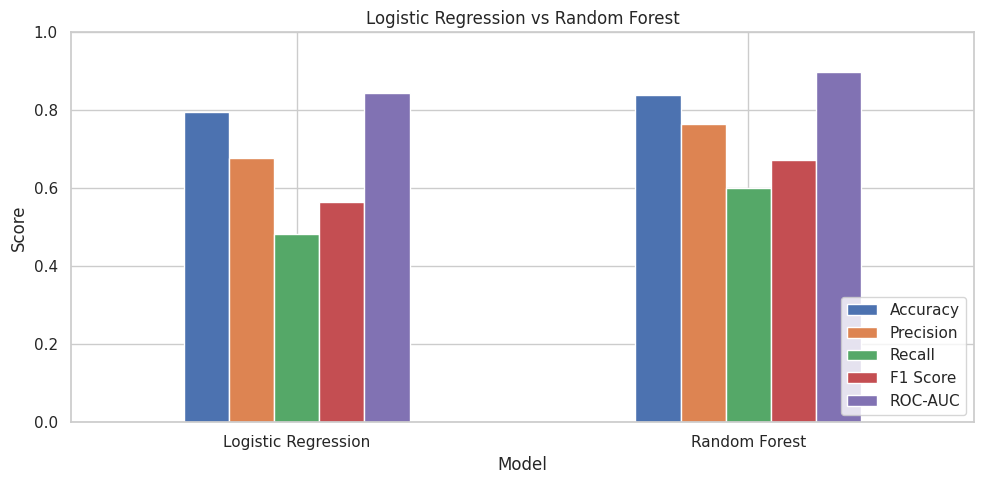

In [112]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

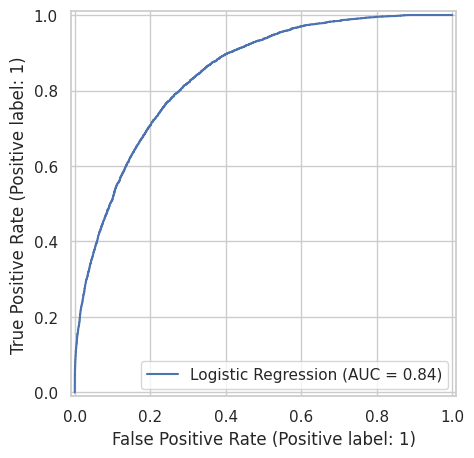

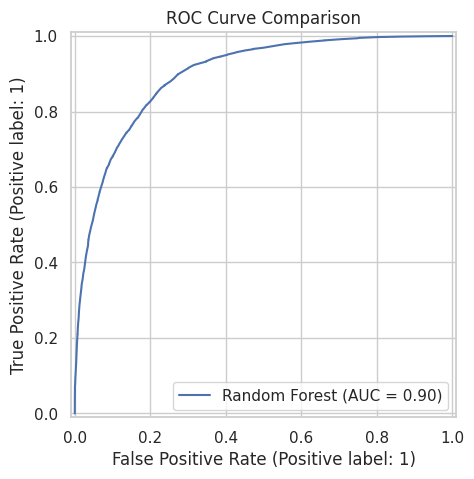

In [113]:
RocCurveDisplay.from_predictions(
    y_test,
    lr_probabilities,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest"
)

plt.title("ROC Curve Comparison")
plt.show()